<a href="https://colab.research.google.com/github/shahed447/Copy_of_DA_360_Project.ipynb/blob/main/Another_copy_of_DA_360_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import glob
import hashlib
import numpy as np
import cv2
import matplotlib.pyplot as plt
import kagglehub

In [ ]:
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, ConfusionMatrixDisplay)
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
SAVE_DIR = "/content/drive/MyDrive/DA360_project_all_crops"
os.makedirs(SAVE_DIR, exist_ok=True)

In [ ]:
IMG_SIZE = 128
PER_CLASS = None
path = kagglehub.dataset_download("tushar5harma/plant-village-dataset-updated")

100%|██████████| 1.00G/1.00G [00:08<00:00, 127MB/s]

Extracting files...


In [ ]:
BASE_DIR = path
for root, dirs, files in os.walk(path):
    if len(dirs) >= 5 and "Tomato" in dirs:
        BASE_DIR = root
        break


plant_folders = sorted([
    d for d in os.listdir(BASE_DIR)
    if os.path.isdir(os.path.join(BASE_DIR, d))
])

print("المجلد الرئيسي (Base folder):", BASE_DIR)
print("عدد النباتات الموجودة:", len(plant_folders))
print("قائمة جميع النباتات:", plant_folders)

المجلد الرئيسي (Base folder): /root/.cache/kagglehub/datasets/tushar5harma/plant-village-dataset-updated/versions/2
عدد النباتات الموجودة: 9
قائمة جميع النباتات: ['Apple', 'Bell Pepper', 'Cherry', 'Corn (Maize)', 'Grape', 'Peach', 'Potato', 'Strawberry', 'Tomato']


In [ ]:
splits_map = {"train": {}, "val": {}, "test": {}}

for plant in plant_folders:
    plant_path = os.path.join(BASE_DIR, plant)
    subfolders = [
        d for d in os.listdir(plant_path)
        if os.path.isdir(os.path.join(plant_path, d))
    ]


    split_dirs = {
        "train": next((d for d in subfolders if "train" in d.lower()), None),
        "val":   next((d for d in subfolders if "val" in d.lower()), None),
        "test":  next((d for d in subfolders if "test" in d.lower()), None),
    }




    for split_key, folder_name in split_dirs.items():
        if folder_name is None:
            continue
        split_path = os.path.join(plant_path, folder_name)
        for disease in os.listdir(split_path):
            disease_dir = os.path.join(split_path, disease)
            if os.path.isdir(disease_dir):

                full_class_name = f"{plant}_{disease}".strip("_ ")
                splits_map[split_key][full_class_name] = disease_dir


In [ ]:
class_names = sorted(splits_map["train"].keys())

print("\nإجمالي عدد الفئات عبر جميع النباتات:", len(class_names))
print("أول 10 فئات كمثال:", class_names[:10])


إجمالي عدد الفئات عبر جميع النباتات: 29
أول 10 فئات كمثال: ['Apple_Apple Scab', 'Apple_Black Rot', 'Apple_Cedar Apple Rust', 'Apple_Healthy', 'Bell Pepper_Bacterial Spot', 'Bell Pepper_Healthy', 'Cherry_Healthy', 'Cherry_Powdery Mildew', 'Corn (Maize)_Cercospora Leaf Spot', 'Corn (Maize)_Common Rust']


In [ ]:
IMG_SIZE = 128
PER_CLASS = 50
seen_hashes = set()
stats = {"broken": 0, "duplicates": 0}

def load_and_clean_all(split_key, limit=None):
    images, labels = [], []

    for label, class_name in enumerate(class_names):
        class_dir = splits_map[split_key].get(class_name)
        if not class_dir:
            continue

        files = sorted(glob.glob(os.path.join(class_dir, "*")))
        if limit:
            files = files[:limit]

        for f in files:
            if not os.path.isfile(f):
                continue
            img = cv2.imread(f)
            if img is None:
                stats["broken"] += 1
                continue

            img_hash = hashlib.md5(img.tobytes()).hexdigest()
            if img_hash in seen_hashes:
                stats["duplicates"] += 1
                continue
            seen_hashes.add(img_hash)

            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))

            images.append(img)
            labels.append(label)

    return np.array(images), np.array(labels)

In [ ]:
X_train, y_train = load_and_clean_all("train", limit=PER_CLASS)
X_val, y_val     = load_and_clean_all("val",   limit=int(PER_CLASS * 0.2) if PER_CLASS else None)
X_test, y_test   = load_and_clean_all("test",  limit=int(PER_CLASS * 0.2) if PER_CLASS else None)

print("\n------------------------------------------------------------")
print(f"Broken removed: {stats['broken']} | Duplicates removed: {stats['duplicates']}")
print(f"Train: {len(X_train)} | Validation: {len(X_val)} | Test: {len(X_test)}")


------------------------------------------------------------
Broken removed: 0 | Duplicates removed: 0
Train: 1450 | Validation: 290 | Test: 290


In [ ]:
# ==========================================
# STEP 1: FEATURE EXTRACTION (GLCM + LBP)
# ==========================================

from skimage.feature import graycomatrix, graycoprops, local_binary_pattern

def extract_features(images):

    features = []

    P = 8
    R = 1

    distances = [1, 2]
    angles = [0, np.pi/4, np.pi/2, 3*np.pi/4]

    for img in images:

        # Convert RGB image to grayscale
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

        # GLCM Features
        glcm = graycomatrix(
            gray,
            distances=distances,
            angles=angles,
            levels=256,
            symmetric=True,
            normed=True
        )

        glcm_features = []

        for prop in [
            'contrast',
            'dissimilarity',
            'homogeneity',
            'energy',
            'correlation',
            'ASM'
        ]:
            values = graycoprops(glcm, prop)
            glcm_features.extend([
                np.nan_to_num(values.mean()),
                np.nan_to_num(values.std())
            ])

        # LBP Features
        lbp = local_binary_pattern(
            gray, P, R, method='uniform'
        )

        lbp_hist, _ = np.histogram(
            lbp.ravel(),
            bins=np.arange(0, P + 3),
            range=(0, P + 2)
        )

        lbp_hist = lbp_hist.astype(float)
        lbp_hist /= (lbp_hist.sum() + 1e-7)

        # Color Features
        color_features = []

        for channel in range(3):

            channel_data = img[:, :, channel]

            color_features.extend([
                channel_data.mean(),
                channel_data.std()
            ])

            hist, _ = np.histogram(
                channel_data,
                bins=8,
                range=(0, 256)
            )

            hist = hist.astype(float)
            hist /= (hist.sum() + 1e-7)

            color_features.extend(hist)

        # Combine all features
        combined = (
            glcm_features +
            lbp_hist.tolist() +
            color_features
        )

        features.append(combined)

    return np.array(features, dtype=np.float32)


# Extract features from all datasets
X_train_features = extract_features(X_train)
X_val_features = extract_features(X_val)
X_test_features = extract_features(X_test)

print("Feature Extraction Completed Successfully!")

print("Training Features:", X_train_features.shape)
print("Validation Features:", X_val_features.shape)
print("Testing Features:", X_test_features.shape)

Feature Extraction Completed Successfully!
Training Features: (1450, 52)
Validation Features: (290, 52)
Testing Features: (290, 52)


In [ ]:
# ==========================================
# STEP 2: FEATURE SCALING
# ==========================================

scaler = StandardScaler()

# Fit only on training data
X_train_scaled = scaler.fit_transform(X_train_features)

# Transform validation and testing data
X_val_scaled = scaler.transform(X_val_features)
X_test_scaled = scaler.transform(X_test_features)

print("Feature Scaling Completed Successfully!")

print("Training:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Testing:", X_test_scaled.shape)

Feature Scaling Completed Successfully!
Training: (1450, 52)
Validation: (290, 52)
Testing: (290, 52)


In [ ]:
# ==========================================
# STEP 3: TRAIN MACHINE LEARNING MODELS
# ==========================================

models = {
    "KNN": KNeighborsClassifier(n_neighbors=5),

    "SVM": SVC(kernel='rbf', C=1.0, random_state=42),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "Naive Bayes": GaussianNB()
}

results = []

for name, model in models.items():

    print(f"\nTraining {name}...")

    model.fit(X_train_scaled, y_train)

    val_predictions = model.predict(X_val_scaled)

    accuracy = accuracy_score(y_val, val_predictions)

    precision = precision_score(
        y_val, val_predictions,
        average='weighted',
        zero_division=0
    )

    recall = recall_score(
        y_val, val_predictions,
        average='weighted',
        zero_division=0
    )

    f1 = f1_score(
        y_val, val_predictions,
        average='weighted',
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

    print(f"{name} Training Completed!")

print("\nAll Models Trained Successfully!")


Training KNN...
KNN Training Completed!

Training SVM...
SVM Training Completed!

Training Random Forest...
Random Forest Training Completed!

Training Naive Bayes...
Naive Bayes Training Completed!

All Models Trained Successfully!


Machine Learning Models Comparison:


,Model,Accuracy,Precision,Recall,F1-Score
0,Random Forest,0.827586,0.842229,0.827586,0.824460
1,SVM,0.741379,0.745721,0.741379,0.731097
2,KNN,0.644828,0.664104,0.644828,0.636744
3,Naive Bayes,0.413793,0.516248,0.413793,0.391739


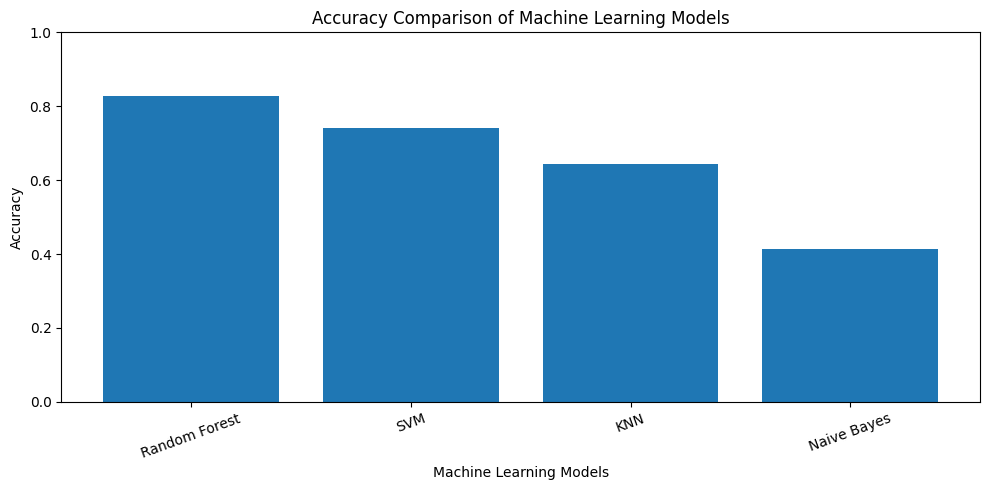

In [ ]:
# ==========================================
# STEP 4: MODEL COMPARISON
# ==========================================

import pandas as pd

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

print("Machine Learning Models Comparison:")
display(results_df)

plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Model"],
    results_df["Accuracy"]
)

plt.title("Accuracy Comparison of Machine Learning Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [ ]:
# ==========================================
# STEP 5: FINAL MODEL EVALUATION
# ==========================================

from sklearn.metrics import classification_report

# Select the best model based on validation results
best_model_name = results_df.iloc[0]["Model"]
best_model = models[best_model_name]

print("Best Model:", best_model_name)

# Predict on unseen test data
y_test_pred = best_model.predict(X_test_scaled)

# Calculate final evaluation metrics
test_accuracy = accuracy_score(y_test, y_test_pred)

test_precision = precision_score(
    y_test, y_test_pred,
    average='weighted',
    zero_division=0
)

test_recall = recall_score(
    y_test, y_test_pred,
    average='weighted',
    zero_division=0
)

test_f1 = f1_score(
    y_test, y_test_pred,
    average='weighted',
    zero_division=0
)

print("\nFinal Test Results")
print("----------------------------")
print(f"Accuracy:  {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall:    {test_recall:.4f}")
print(f"F1-Score:  {test_f1:.4f}")

# Detailed Classification Report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    zero_division=0
))

Best Model: Random Forest

Final Test Results
----------------------------
Accuracy:  0.6414
Precision: 0.6506
Recall:    0.6414
F1-Score:  0.6296

Classification Report:
                                   precision    recall  f1-score   support

                 Apple_Apple Scab       0.64      0.70      0.67        10
                  Apple_Black Rot       0.55      0.60      0.57        10
           Apple_Cedar Apple Rust       0.67      0.40      0.50        10
                    Apple_Healthy       0.80      0.80      0.80        10
       Bell Pepper_Bacterial Spot       0.83      0.50      0.62        10
              Bell Pepper_Healthy       0.36      0.40      0.38        10
                   Cherry_Healthy       0.86      0.60      0.71        10
            Cherry_Powdery Mildew       0.50      0.70      0.58        10
Corn (Maize)_Cercospora Leaf Spot       0.67      0.40      0.50        10
         Corn (Maize)_Common Rust       1.00      1.00      1.00        10
   

In [ ]:
# ==========================================
# STEP 7: SAVE THE BEST MACHINE LEARNING MODEL
# ==========================================

import joblib
import json
import os
import pandas as pd
import numpy as np

# Create project folder
os.makedirs(SAVE_DIR, exist_ok=True)

# Save the best trained model
joblib.dump(
    best_model,
    os.path.join(SAVE_DIR, "best_plant_disease_model.pkl")
)

# Save the scaler
joblib.dump(
    scaler,
    os.path.join(SAVE_DIR, "feature_scaler.pkl")
)

# Save class names
with open(
    os.path.join(SAVE_DIR, "class_names.json"),
    "w"
) as file:
    json.dump(class_names, file, indent=4)

# Save model comparison results
results_df.to_csv(
    os.path.join(SAVE_DIR, "model_comparison.csv"),
    index=False
)

# Save final test metrics
test_metrics = pd.DataFrame([{
    "Model": best_model_name,
    "Accuracy": test_accuracy,
    "Precision": test_precision,
    "Recall": test_recall,
    "F1-Score": test_f1
}])

test_metrics.to_csv(
    os.path.join(SAVE_DIR, "final_test_results.csv"),
    index=False
)

# Save classification report
report = classification_report(
    y_test,
    y_test_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    zero_division=0
)

with open(
    os.path.join(SAVE_DIR, "classification_report.txt"),
    "w"
) as file:
    file.write(report)

# Save confusion matrix
np.save(
    os.path.join(SAVE_DIR, "confusion_matrix.npy"),
    cm
)

# Save predictions
predictions_df = pd.DataFrame({
    "Actual": [class_names[i] for i in y_test],
    "Predicted": [class_names[i] for i in y_test_pred]
})

predictions_df.to_csv(
    os.path.join(SAVE_DIR, "test_predictions.csv"),
    index=False
)

print("All project files saved successfully!")
print("\nSaved files:")

for file_name in os.listdir(SAVE_DIR):
    print("-", file_name)

print("\nBest Model:", best_model_name)
print("Save Location:", SAVE_DIR)

All project files saved successfully!

Saved files:
- best_plant_disease_model.pkl
- feature_scaler.pkl
- class_names.json
- model_comparison.csv
- final_test_results.csv
- classification_report.txt
- confusion_matrix.npy
- test_predictions.csv
- best_model.pkl
- scaler.pkl
- class_names.pkl

Best Model: Random Forest
Save Location: /content/drive/MyDrive/DA360_project_all_crops


In [ ]:
import joblib

# Save the trained model
joblib.dump(best_model, 'plant_disease_model.pkl')

# Save the scaler
joblib.dump(scaler, 'feature_scaler.pkl')

# Save class names
joblib.dump(class_names, 'class_names.pkl')

print("Model saved successfully!")

Model saved successfully!


In [ ]:
import os
import joblib

# Create save directory
os.makedirs(SAVE_DIR, exist_ok=True)

# Save trained model and scaler
joblib.dump(best_model, os.path.join(SAVE_DIR, "best_model.pkl"))
joblib.dump(scaler, os.path.join(SAVE_DIR, "scaler.pkl"))

# Save class names
joblib.dump(class_names, os.path.join(SAVE_DIR, "class_names.pkl"))

print("Model saved successfully!")
print("Best Model:", best_model_name)
print("All files saved in:", SAVE_DIR)

Model saved successfully!
Best Model: Random Forest
All files saved in: /content/drive/MyDrive/DA360_project_all_crops


In [ ]:
import os

print(os.listdir(SAVE_DIR))

['best_plant_disease_model.pkl', 'feature_scaler.pkl', 'class_names.json', 'model_comparison.csv', 'final_test_results.csv', 'classification_report.txt', 'confusion_matrix.npy', 'test_predictions.csv', 'best_model.pkl', 'scaler.pkl', 'class_names.pkl']


In [ ]:
import joblib
import os

model = joblib.load(os.path.join(SAVE_DIR, "best_plant_disease_model.pkl"))

print("Model loaded successfully!")
print("Model type:", type(model).__name__)

Model loaded successfully!
Model type: RandomForestClassifier


In [ ]:
import pandas as pd
import os

# Load final test results
results = pd.read_csv(os.path.join(SAVE_DIR, "final_test_results.csv"))

print("Final Test Results:")
display(results)

# Load model comparison
comparison = pd.read_csv(os.path.join(SAVE_DIR, "model_comparison.csv"))

print("Model Comparison:")
display(comparison)


Final Test Results:


,Model,Accuracy,Precision,Recall,F1-Score
0,Random Forest,0.641379,0.650555,0.641379,0.629634


Model Comparison:


,Model,Accuracy,Precision,Recall,F1-Score
0,Random Forest,0.827586,0.842229,0.827586,0.824460
1,SVM,0.741379,0.745721,0.741379,0.731097
2,KNN,0.644828,0.664104,0.644828,0.636744
3,Naive Bayes,0.413793,0.516248,0.413793,0.391739


In [ ]:
import os
import zipfile

zip_path = "/content/drive/MyDrive/DA360_Final_Results.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for file in os.listdir(SAVE_DIR):
        if file.endswith((".pkl", ".json", ".csv")):
            file_path = os.path.join(SAVE_DIR, file)

            if os.path.isfile(file_path):
                zipf.write(file_path, arcname=file)

print("Project files collected successfully!")
print("ZIP file:", zip_path)
print("ZIP size:", round(os.path.getsize(zip_path) / 1024 / 1024, 2), "MB")

Project files collected successfully!
ZIP file: /content/drive/MyDrive/DA360_Final_Results.zip
ZIP size: 3.27 MB


In [ ]:
# ==========================================
# STEP 14: CROSS VALIDATION
# ==========================================

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone
import numpy as np
import pandas as pd
import os

# Determine number of folds safely
_, class_counts = np.unique(y_train, return_counts=True)

n_splits = min(5, int(class_counts.min()))

if n_splits < 2:
    raise ValueError("Not enough training samples for Cross Validation.")

# Create cross-validation strategy
cv = StratifiedKFold(
    n_splits=n_splits,
    shuffle=True,
    random_state=42
)

# Create pipeline to avoid data leakage
cv_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", clone(best_model))
])

# Perform cross-validation
cv_results = cross_validate(
    cv_model,
    X_train_features,
    y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "f1_weighted": "f1_weighted"
    },
    n_jobs=1
)

# Calculate results
accuracy_scores = cv_results["test_accuracy"]
f1_scores = cv_results["test_f1_weighted"]

cv_summary = pd.DataFrame({
    "Fold": np.arange(1, n_splits + 1),
    "Accuracy": accuracy_scores,
    "F1-Score": f1_scores
})

print("Cross Validation Results:")
display(cv_summary)

print("\nCross Validation Summary")
print("------------------------------")
print(f"Average Accuracy: {accuracy_scores.mean():.4f}")
print(f"Accuracy Std: {accuracy_scores.std():.4f}")
print(f"Average F1-Score: {f1_scores.mean():.4f}")
print(f"F1-Score Std: {f1_scores.std():.4f}")

# Save results
cv_summary.to_csv(
    os.path.join(SAVE_DIR, "cross_validation_results.csv"),
    index=False
)

print("\nCross Validation Completed Successfully!")


Cross Validation Results:


,Fold,Accuracy,F1-Score
0,1,0.820690,0.808150
1,2,0.800000,0.795152
2,3,0.844828,0.839603
3,4,0.806897,0.801357
4,5,0.844828,0.836878



Cross Validation Summary
------------------------------
Average Accuracy: 0.8234
Accuracy Std: 0.0187
Average F1-Score: 0.8162
F1-Score Std: 0.0185

Cross Validation Completed Successfully!


In [ ]:
# ==========================================
# STEP 15: FINAL MODEL PERFORMANCE SUMMARY
# ==========================================

import os
import pandas as pd
import numpy as np

# Create final summary
summary = {
    "Best Model": best_model_name,
    "Number of Classes": len(class_names),
    "Training Images": len(X_train),
    "Testing Images": len(X_test),
    "Test Accuracy": test_accuracy,
    "Test Precision": test_precision,
    "Test Recall": test_recall,
    "Test F1-Score": test_f1,
    "Cross Validation Accuracy": cv_summary["Accuracy"].mean(),
    "Cross Validation F1-Score": cv_summary["F1-Score"].mean()
}

summary_df = pd.DataFrame([summary])

print("FINAL MACHINE LEARNING PROJECT SUMMARY")
print("========================================")

display(summary_df)

# Save final summary
summary_df.to_csv(
    os.path.join(SAVE_DIR, "final_project_summary.csv"),
    index=False
)

# Create text report
report_path = os.path.join(
    SAVE_DIR,
    "final_machine_learning_summary.txt"
)

with open(report_path, "w") as file:

    file.write("PLANT DISEASE CLASSIFICATION PROJECT\n")
    file.write("FINAL MACHINE LEARNING SUMMARY\n")
    file.write("=" * 45 + "\n\n")

    file.write(f"Best Model: {best_model_name}\n")
    file.write(f"Number of Classes: {len(class_names)}\n")
    file.write(f"Training Images: {len(X_train)}\n")
    file.write(f"Testing Images: {len(X_test)}\n\n")

    file.write("FINAL TEST RESULTS\n")
    file.write("-" * 30 + "\n")
    file.write(f"Accuracy: {test_accuracy:.4f}\n")
    file.write(f"Precision: {test_precision:.4f}\n")
    file.write(f"Recall: {test_recall:.4f}\n")
    file.write(f"F1-Score: {test_f1:.4f}\n\n")

    file.write("CROSS VALIDATION RESULTS\n")
    file.write("-" * 30 + "\n")
    file.write(
        f"Average Accuracy: {cv_summary['Accuracy'].mean():.4f}\n"
    )
    file.write(
        f"Average F1-Score: {cv_summary['F1-Score'].mean():.4f}\n"
    )

print("\nFinal Project Summary Created Successfully!")
print("Report saved at:", report_path)

FINAL MACHINE LEARNING PROJECT SUMMARY


,Best Model,Number of Classes,Training Images,Testing Images,Test Accuracy,Test Precision,Test Recall,Test F1-Score,Cross Validation Accuracy,Cross Validation F1-Score
0,Random Forest,29,1450,290,0.641379,0.650555,0.641379,0.629634,0.823448,0.816228



Final Project Summary Created Successfully!
Report saved at: /content/drive/MyDrive/DA360_project_all_crops/final_machine_learning_summary.txt
